# Preprocessing: a 5 × 5 km study grid and daily FIRMS labels

Create full squares over the five Indonesian Kalimantan provinces, flag those
intersecting the downloaded BIG peatland layer, then assign high-confidence
FIRMS detections within that mask to cells and dates. Weather and other
predictors have not yet been attached.

Mahdiyasa et al. (2026), §2.2.2, specifies 5 × 5 km cells but does not specify
the projection, origin, or cell-inclusion rule. The choices below are our
documented reconstruction, pending visual review against the paper.

**Mask caveat:** use all 146 polygons in the BIG download. Some landform names
do not contain “Gambut”; their soil attributes may still indicate organic soils.
This is a candidate mapped mask, not a newly validated peat classification.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
import pyproj
from pyproj import CRS, Geod, Transformer
import shapely
from shapely.geometry import mapping, shape
from shapely.ops import transform
from shapely.plotting import plot_polygon

ROOT = Path.cwd()
BOUNDARY_PATH = ROOT / "data/raw/boundaries/big_kalimantan_provinces.geojson"
PEAT_PATH = ROOT / "data/raw/peatland/big_peta_lahan_gambut_kalimantan.geojson"
OUTPUT_DIR = ROOT / "data/interim/study_grid_5km"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 5 km grids (use meters cuz its more accurate than angles)
# Longitude and Latitude are angles, so degree spacing varies in ground distance.
CELL_M = 5_000
SOURCE_CRS = CRS.from_epsg(4326)  # downloaded GeoJSON longitude/latitude

# lat_0 and lon_0 centers the projection to kalimantan
GRID_CRS_PROJ = "+proj=laea +lat_0=0 +lon_0=114 +datum=WGS84 +units=m +no_defs"
GRID_CRS = CRS.from_proj4(GRID_CRS_PROJ)
to_grid = Transformer.from_crs(SOURCE_CRS, GRID_CRS, always_xy=True)
to_lonlat = Transformer.from_crs(GRID_CRS, SOURCE_CRS, always_xy=True)

## 1. Load unsimplified polygons and project into metres

Longitude/latitude degrees do not have a fixed length in kilometres. Use one
Lambert azimuthal equal-area (LAEA) projection centered at 114°E, 0°N for the
whole region, rather than joining grids from multiple UTM zones. Equal area
makes overlap fractions straightforward. Each square is exactly 5,000 m per
side **in this projection**; ground distances vary slightly. We measure that
variation below.

The province GeoJSON contains Z/M coordinates; discard those extra values.
Reject invalid or empty geometry rather than silently repairing source data.
Dissolve overlapping polygons to avoid counting the same area twice, and
restrict the candidate BIG mask to the province union. No simplified geometry
is used for grid creation, inclusion, or overlap calculations.

In [2]:
def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]


def load_polygons(path):
    document = json.loads(path.read_text(encoding="utf-8"))
    features = document["features"]
    geometries = np.array([
        shape({"type": feature["geometry"]["type"],
               "coordinates": keep_xy(feature["geometry"]["coordinates"])})
        for feature in features
    ], dtype=object)
    if not shapely.is_valid(geometries).all():
        raise ValueError(f"Invalid geometry in {path}")
    return features, geometries


province_features, province_ll = load_polygons(BOUNDARY_PATH)
peat_features, peat_ll = load_polygons(PEAT_PATH)
provinces = np.array([transform(to_grid.transform, g) for g in province_ll])
peat_polygons = np.array([transform(to_grid.transform, g) for g in peat_ll])
study_area = shapely.union_all(provinces)
mapped_union = shapely.union_all(peat_polygons)
mapped_in_study = shapely.intersection(mapped_union, study_area)

print("Provinces:", ", ".join(f["properties"]["WADMPR"] for f in province_features))
print(f"Candidate BIG polygons: {len(peat_features):,}")
print(f"Province union: {study_area.area / 1e6:,.1f} km²")
print(f"Dissolved candidate BIG mask within provinces: {mapped_in_study.area / 1e6:,.1f} km²")
print(f"Candidate BIG area outside provinces: {(mapped_union.area - mapped_in_study.area) / 1e6:,.1f} km²")

Provinces: Kalimantan Barat, Kalimantan Tengah, Kalimantan Selatan, Kalimantan Timur, Kalimantan Utara
Candidate BIG polygons: 146
Province union: 534,702.8 km²
Dissolved candidate BIG mask within provinces: 45,281.9 km²
Candidate BIG area outside provinces: 0.0 km²


## 2. Build a reproducible square lattice

Anchor the lattice at projected (0, 0), with cell edges at integer multiples of
5,000 m. Integer `grid_col` and `grid_row` identify a cell even if the study
extent changes later; rows increase **northward**. `cell_id` combines those
indices. Future image tensors will need to account for that row direction.

Keep cells with **positive-area overlap** with the province union, including
coastal and international-border cells. Keep their full square geometry;
clipping squares would create irregular cells. `study_fraction` records the
part inside the provinces. Full-cell areas must not be summed to estimate land
or peat area.

For speed, calculate exact intersections in 100 km tiles. Because 100 km is
a multiple of 5 km, each square lies entirely in its assigned tile; no cell
is cut or moved by this calculation.

In [3]:
min_x, min_y, max_x, max_y = study_area.bounds
col_start, row_start = np.floor(np.array([min_x, min_y]) / CELL_M).astype(int)
col_stop, row_stop = np.ceil(np.array([max_x, max_y]) / CELL_M).astype(int)
cols, rows = np.meshgrid(np.arange(col_start, col_stop), np.arange(row_start, row_stop))
cols, rows = cols.ravel(), rows.ravel()
x0, y0 = cols * CELL_M, rows * CELL_M
candidates = shapely.box(x0, y0, x0 + CELL_M, y0 + CELL_M)

# Fast predicate first; calculate exact areas only for intersecting candidates.
shapely.prepare(study_area)
hits = shapely.intersects(study_area, candidates)
study_area_m2 = np.zeros(len(candidates))
def overlap_areas(squares, mask):
    """Exact overlay in 100 km tiles; keep the full source detail locally."""
    bounds = shapely.bounds(squares)
    tile_keys = np.floor(bounds[:, :2] / 100_000).astype(int)
    areas = np.zeros(len(squares))
    for tile_col, tile_row in np.unique(tile_keys, axis=0):
        selected = np.flatnonzero((tile_keys == [tile_col, tile_row]).all(axis=1))
        tile = shapely.box(tile_col * 100_000, tile_row * 100_000,
                           (tile_col + 1) * 100_000, (tile_row + 1) * 100_000)
        local_mask = shapely.intersection(mask, tile)
        if not local_mask.is_empty:
            areas[selected] = shapely.area(shapely.intersection(squares[selected], local_mask))
    return areas


study_area_m2[hits] = overlap_areas(candidates[hits], study_area)
keep = study_area_m2 > 0
cells = candidates[keep]
grid = pd.DataFrame({
    "cell_id": [f"kp5_c{c}_r{r}" for c, r in zip(cols[keep], rows[keep])],
    "grid_col": cols[keep], "grid_row": rows[keep],
    "x_min_m": x0[keep], "y_min_m": y0[keep],
    "x_center_m": x0[keep] + CELL_M / 2,
    "y_center_m": y0[keep] + CELL_M / 2,
    "cell_area_km2": CELL_M**2 / 1e6,
    "study_fraction": study_area_m2[keep] / CELL_M**2,
})
print(f"Bounding rectangle: {row_stop-row_start} rows × {col_stop-col_start} columns")
print(f"Cells overlapping Kalimantan: {len(grid):,}")

Bounding rectangle: 208 rows × 234 columns
Cells overlapping Kalimantan: 22,336


## 3. Flag candidate BIG intersections and measure coverage

`intersects_big_peatland` means that the full square intersects the dissolved
BIG mask **within Kalimantan**, including boundary-only touches.
`big_peatland_area_km2` measures the actual overlap;
`big_peatland_fraction` divides it by the full 25 km² square. Also retain
`has_positive_big_overlap` to distinguish any zero-area touches.

There is no minimum peat fraction at this stage. A flagged square may contain
mostly non-peat land or sea; the flag does not mean that every point in the
square is peatland. These columns let us inspect sensitivity before adopting
a final study-cell rule.

In [4]:
shapely.prepare(mapped_in_study)
intersects_big = shapely.intersects(mapped_in_study, cells)
overlap_m2 = np.zeros(len(cells))
overlap_m2[intersects_big] = overlap_areas(cells[intersects_big], mapped_in_study)
grid["intersects_big_peatland"] = intersects_big
grid["has_positive_big_overlap"] = overlap_m2 > 0
grid["big_peatland_area_km2"] = overlap_m2 / 1e6
grid["big_peatland_fraction"] = overlap_m2 / CELL_M**2

summary = pd.Series({
    "Kalimantan cells": len(grid),
    "Cells intersecting candidate BIG mask": int(intersects_big.sum()),
    "Cells with positive BIG overlap": int((overlap_m2 > 0).sum()),
    "Boundary-only BIG touches": int((intersects_big & (overlap_m2 == 0)).sum()),
    "Cells with at least 50% BIG coverage": int((grid.big_peatland_fraction >= 0.5).sum()),
}, name="cell_count")
print(summary.to_string())
grid.loc[intersects_big, "big_peatland_fraction"].describe().to_frame()

Kalimantan cells                         22336
Cells intersecting candidate BIG mask     3512
Cells with positive BIG overlap           3512
Boundary-only BIG touches                    0
Cells with at least 50% BIG coverage      1746


,big_peatland_fraction
count,3.512000e+03
mean,5.157393e-01
std,3.683512e-01
min,3.228998e-07
25%,1.471483e-01
50%,4.955544e-01
75%,9.122930e-01
max,1.000000e+00


## 4. Check size, coverage, and projection distortion

The sum of per-cell overlaps should recover the dissolved province and BIG
areas. These checks catch missing cells, double counting, and broken geometry.
Inverse-project every square corner and measure all four edges geodesically
on WGS84 to quantify how projected 5 km sides differ from ground distances.

In [5]:
# The summed overlaps should recover the original province and peat areas.
if not np.isclose(study_area_m2[keep].sum(), study_area.area, rtol=1e-8):
    raise ValueError("Study-grid cells do not cover the full province area")
if not np.isclose(overlap_m2.sum(), mapped_in_study.area, rtol=1e-8):
    raise ValueError("Study-grid cells do not cover the full peat mask")

corners = shapely.get_coordinates(cells).reshape(-1, 5, 2)
corner_lon, corner_lat = to_lonlat.transform(corners[:, :, 0], corners[:, :, 1])
_, _, edge_m = Geod(ellps="WGS84").inv(
    corner_lon[:, :-1], corner_lat[:, :-1], corner_lon[:, 1:], corner_lat[:, 1:]
)
print("Grid covers the province and peat areas.")
print(f"WGS84 ground edge lengths: {edge_m.min():,.2f}–{edge_m.max():,.2f} m")
print(f"Largest ground-length departure from 5 km: {np.max(np.abs(edge_m / CELL_M - 1)) * 100:.3f}%")

Grid covers the province and peat areas.
WGS84 ground edge lengths: 4,994.38–5,005.58 m
Largest ground-length departure from 5 km: 0.112%


## 5. Map for review

The overview shows flagged squares over all five provinces. The close-up near
113°E, 2.5°S shows the original BIG outlines and individual squares: flagged
cells extend beyond polygon edges because we keep whole squares. Coordinates
are kilometres in the local LAEA projection, not longitude/latitude.
Province outlines are simplified by 100 m **only for display**.

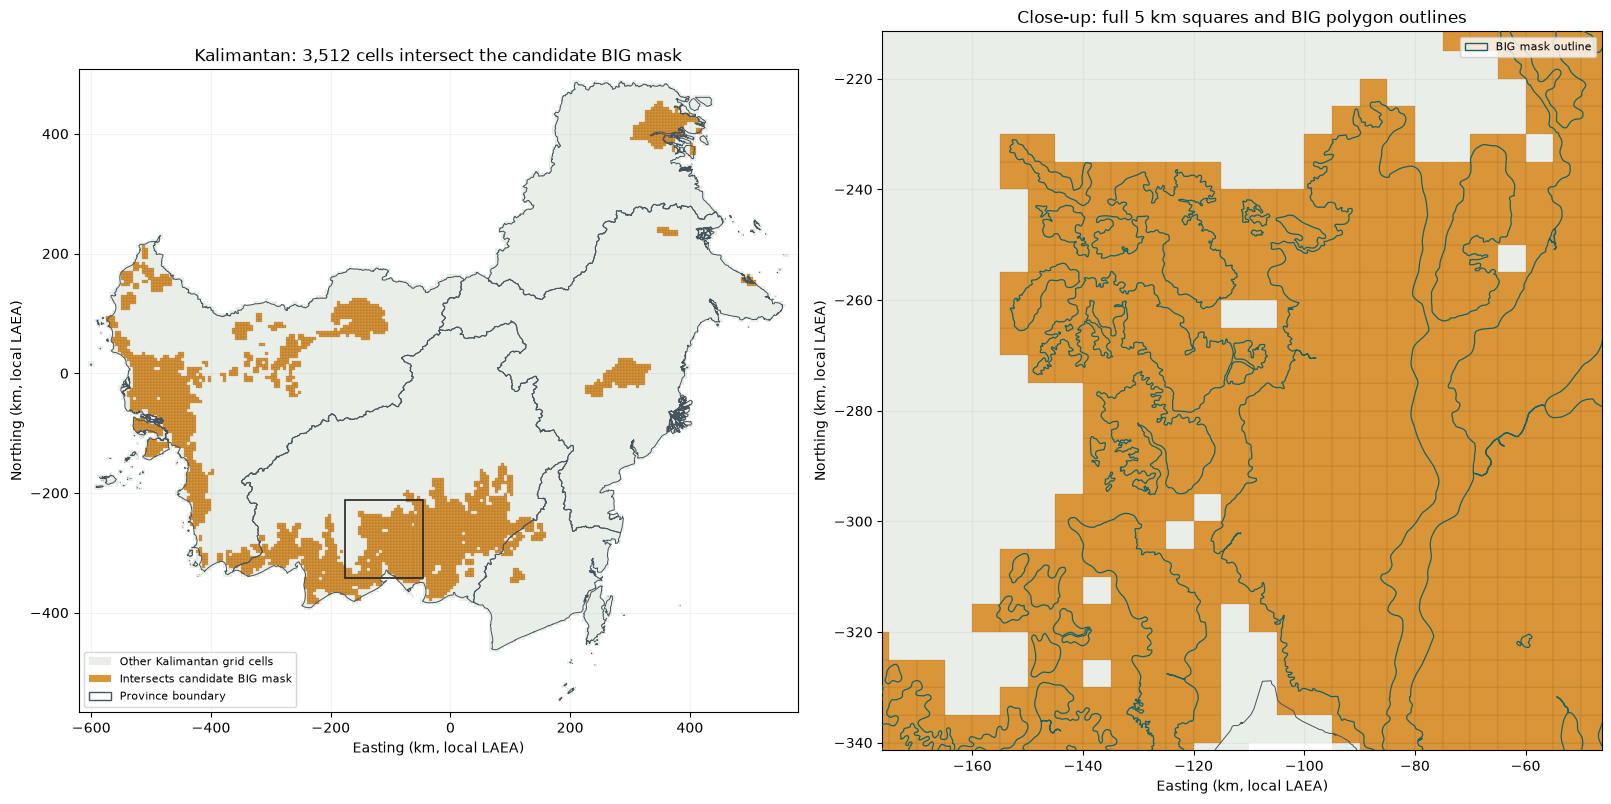

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
vertices_km = corners[:, :4, :] / 1000
for ax in axes:
    ax.add_collection(PolyCollection(vertices_km, facecolors="#e9eee9",
                                    edgecolors="none", zorder=1))
    ax.add_collection(PolyCollection(vertices_km[intersects_big], facecolors="#d99537",
                                    edgecolors="#81551f", linewidths=0.12, zorder=2))
    for province in provinces:
        plot_polygon(shapely.transform(province.simplify(100), lambda xy: xy / 1000),
                     ax=ax, add_points=False, facecolor="none",
                     edgecolor="#46545c", linewidth=0.7, zorder=3)
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (km, local LAEA)")
    ax.set_ylabel("Northing (km, local LAEA)")
    ax.grid(alpha=0.15)

axes[0].set_xlim(min_x / 1000 - 20, max_x / 1000 + 20)
axes[0].set_ylim(min_y / 1000 - 20, max_y / 1000 + 20)
axes[0].set_title(f"Kalimantan: {intersects_big.sum():,} cells intersect the candidate BIG mask")
zoom_x, zoom_y = np.array(to_grid.transform(113, -2.5)) / 1000
half_width = 65
zoom_bounds = (zoom_x-half_width, zoom_y-half_width, zoom_x+half_width, zoom_y+half_width)
axes[0].add_patch(Rectangle(zoom_bounds[:2], 2*half_width, 2*half_width,
                            fill=False, edgecolor="#222222", linewidth=1.2, zorder=4))
axes[1].set_xlim(zoom_bounds[0], zoom_bounds[2])
axes[1].set_ylim(zoom_bounds[1], zoom_bounds[3])
plot_polygon(shapely.transform(mapped_in_study, lambda xy: xy / 1000),
             ax=axes[1], add_points=False, facecolor="none", edgecolor="#12636a",
             linewidth=0.9, zorder=4)
axes[1].set_title("Close-up: full 5 km squares and BIG polygon outlines")
axes[0].legend(handles=[
    Patch(facecolor="#e9eee9", label="Other Kalimantan grid cells"),
    Patch(facecolor="#d99537", label="Intersects candidate BIG mask"),
    Patch(facecolor="none", edgecolor="#46545c", label="Province boundary"),
], loc="lower left", fontsize=8)
axes[1].legend(handles=[Patch(facecolor="none", edgecolor="#12636a", label="BIG mask outline")],
               loc="upper right", fontsize=8)
fig.savefig(OUTPUT_DIR / "study_grid_5km.png", dpi=180, facecolor="white")
plt.show()

## 6. Save this candidate grid and its decisions

Save all retained cells, not just flagged ones. The CSV carries attributes;
the GeoJSON carries matching full-square geometries in WGS84 for GIS viewers.
GeoJSON edges are defined by transformed corners; use the projected corner
columns and manifest CRS to reconstruct exact squares for future analysis.
The manifest records source hashes, software versions, CRS, origin, rules,
and counts. Generated files live under the Git-ignored `data/interim/` folder.

These exports describe the spatial grid. The following section creates
in-memory daily FIRMS labels; it does not yet export them or attach predictors.

In [7]:
grid.to_csv(OUTPUT_DIR / "study_grid_5km.csv", index=False)
cells_ll = [transform(to_lonlat.transform, cell) for cell in cells]
geojson = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": row, "geometry": mapping(geometry)}
    for row, geometry in zip(grid.to_dict(orient="records"), cells_ll)
]}
(OUTPUT_DIR / "study_grid_5km.geojson").write_text(json.dumps(geojson), encoding="utf-8")
manifest = {
    "status": "candidate grid pending map and mask review",
    "cell_size_m": CELL_M,
    "grid_crs_proj": GRID_CRS_PROJ,
    "grid_crs_wkt": GRID_CRS.to_wkt(),
    "source_crs": "EPSG:4326 (GeoJSON longitude/latitude)",
    "lattice_origin_m": [0, 0],
    "row_direction": "northward; column direction eastward",
    "cell_id_rule": "kp5_c{grid_col}_r{grid_row}; signed integer lattice indices",
    "bounds_indices_stop_exclusive": {
        "col_start": int(col_start), "col_stop": int(col_stop),
        "row_start": int(row_start), "row_stop": int(row_stop),
    },
    "study_cell_rule": "positive-area overlap with dissolved five-province boundary; keep full squares",
    "big_mask_rule": "all downloaded BIG polygons, dissolved and intersected with province union",
    "big_flag_rule": "intersects, including boundary-only touches; no minimum fraction",
    "fraction_denominator_m2": CELL_M**2,
    "source_polygon_counts": {"provinces": len(province_features), "big": len(peat_features)},
    "counts": {k: int(v) for k, v in summary.items()},
    "province_union_area_km2": study_area.area / 1e6,
    "big_mask_area_in_provinces_km2": mapped_in_study.area / 1e6,
    "ground_edge_length_m": {"min": float(edge_m.min()), "max": float(edge_m.max())},
    "sources": [{"path": str(path.relative_to(ROOT)),
                 "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
                for path in [BOUNDARY_PATH, PEAT_PATH]],
    "software": {"numpy": np.__version__, "pandas": pd.__version__,
                 "shapely": shapely.__version__, "pyproj": pyproj.__version__,
                 "proj": pyproj.proj_version_str},
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
print("Saved:", OUTPUT_DIR.relative_to(ROOT))
print("study_grid_5km.csv, study_grid_5km.geojson, study_grid_5km.png, manifest.json")

Saved: data/interim/study_grid_5km
study_grid_5km.csv, study_grid_5km.geojson, study_grid_5km.png, manifest.json


## 7. FIRMS: load detections and filter by confidence

Keep detections with confidence strictly greater than 80. Each source row is
a satellite detection, not necessarily a separate fire.

In [8]:
firms_path = (
    ROOT / "data/raw/Firms/DL_FIRE_M-C61_814923"
    / "fire_archive_M-C61_814923.csv"
)

firms = pd.read_csv(firms_path, parse_dates=["acq_date"])

high_conf = firms[firms["confidence"] > 80].copy()

print(f'All detections: {len(firms):,}')
print(f'Confidence > 80: {len(high_conf)}')

All detections: 47,686
Confidence > 80: 9472


## 8. Retain detections within the candidate BIG mask

Project detection coordinates into the same metre-based CRS as the mask.
`covers` includes points inside the mask or exactly on its boundary.

In [9]:
fire_x, fire_y = to_grid.transform(
    high_conf['longitude'].to_numpy(),
    high_conf['latitude'].to_numpy(),
)

fire_points = shapely.points(fire_x, fire_y)

high_conf["in_big_peatland"] = shapely.covers(mapped_in_study, fire_points)

peat_fires = high_conf.loc[high_conf['in_big_peatland']].copy()

print(f'High-confidence detections: {len(high_conf)}')
print(f'Inside peatmask: {len(peat_fires)}')

High-confidence detections: 9472
Inside peatmask: 1908


## 9. Select study cells and assign detection cell IDs

Keep all cells intersecting the candidate mask, including cells with no
detections. Divide projected coordinates by 5,000 and floor them to recover
the lattice column and row. Join those addresses to the study grid.

In [10]:
study_grid = grid.loc[
    grid["intersects_big_peatland"]
].copy()

print(f"All Kalimantan cells: {len(grid):,}")
print(f"Candidate peatland study cells: {len(study_grid):,}")

All Kalimantan cells: 22,336
Candidate peatland study cells: 3,512


In [11]:
peat_x, peat_y = to_grid.transform(
    peat_fires['longitude'].to_numpy(),
    peat_fires['latitude'].to_numpy(),
)

peat_fires['grid_col'] = np.floor(peat_x / CELL_M).astype(int)
peat_fires['grid_row'] = np.floor(peat_y / CELL_M).astype(int)

peat_fires = peat_fires.merge(
    study_grid[["grid_col", "grid_row", "cell_id"]],
    on=["grid_col", "grid_row"],
    how="left",
    validate="many_to_one",
)

if peat_fires["cell_id"].isna().any():
    raise ValueError("Some fire detections did not match a study cell")
print("All retained detections matched a study cell.")

peat_fires[
    ["acq_date", "grid_col", "grid_row", "cell_id"]
].head()

All retained detections matched a study cell.


,acq_date,grid_col,grid_row,cell_id
0,2020-03-03,62,1,kp5_c62_r1
1,2020-03-03,62,1,kp5_c62_r1
2,2020-03-11,-105,-4,kp5_c-105_r-4
3,2020-03-11,-106,-5,kp5_c-106_r-5
4,2020-03-11,-106,-5,kp5_c-106_r-5


## 10. Count detections per cell and date

Group retained detections by cell and acquisition date. Multiple detections
in the same group contribute one positive cell-day label.

In [12]:
daily_fire_counts = (
    peat_fires
    .groupby(["cell_id", "acq_date"])
    .size()
    .reset_index(name="detection_count")
)

daily_fire_counts.head(10)

,cell_id,acq_date,detection_count
0,kp5_c-100_r-18,2023-08-29,1
1,kp5_c-100_r-7,2023-08-14,3
2,kp5_c-100_r-7,2023-08-15,4
3,kp5_c-100_r-7,2023-08-17,1
4,kp5_c-100_r-7,2023-08-19,2
5,kp5_c-100_r-8,2023-09-05,1
6,kp5_c-100_r-8,2023-09-27,1
7,kp5_c-100_r34,2024-03-22,1
8,kp5_c-101_r-19,2023-09-05,1
9,kp5_c-101_r-24,2023-09-26,1


## 11. Build the complete daily label table

Pair every study cell with every date from 2020 through 2024. Fill absent
combinations with zero detections, then flag counts greater than zero.
A zero means no qualifying detection recorded, not verified absence of fire;
observation coverage has not been assessed.

In [13]:
dates = pd.date_range("2020-01-01", "2024-12-31", freq="D")
cell_days = pd.MultiIndex.from_product(
    [study_grid["cell_id"], dates],
    names=["cell_id", "acq_date"],
)

print(f"Days: {len(dates):,}")
print(f"Cell-day combinations: {len(cell_days):,}")

daily_labels = (
    daily_fire_counts
    .set_index(['cell_id', 'acq_date'])
    .reindex(cell_days, fill_value=0)
    .reset_index()
)

daily_labels['fire_detected'] = (
    daily_labels['detection_count'] > 0
).astype('int8')

daily_labels.head(10)

Days: 1,827
Cell-day combinations: 6,416,424


,cell_id,acq_date,detection_count,fire_detected
0,kp5_c-48_r-77,2020-01-01,0,0
1,kp5_c-48_r-77,2020-01-02,0,0
2,kp5_c-48_r-77,2020-01-03,0,0
3,kp5_c-48_r-77,2020-01-04,0,0
4,kp5_c-48_r-77,2020-01-05,0,0
5,kp5_c-48_r-77,2020-01-06,0,0
6,kp5_c-48_r-77,2020-01-07,0,0
7,kp5_c-48_r-77,2020-01-08,0,0
8,kp5_c-48_r-77,2020-01-09,0,0
9,kp5_c-48_r-77,2020-01-10,0,0


## 12. Summarize filtering and label balance

A cell-day is one grid cell on one date. Compare the filtering counts and
positive-label share before moving on to predictors or modeling.

In [14]:
pd.Series({
    "Original FIRMS detections": len(firms),
    "After confidence > 80": len(high_conf),
    "Inside candidate BIG peatland mask": len(peat_fires),
    "Distinct cell-days with detections": len(daily_fire_counts),
    "Distinct dates with detections": peat_fires["acq_date"].nunique(),
    "Distinct cells with detections": peat_fires["cell_id"].nunique(),
}, name="count").to_frame()

,count
Original FIRMS detections,47686
After confidence > 80,9472
Inside candidate BIG peatland mask,1908
Distinct cell-days with detections,1009
Distinct dates with detections,171
Distinct cells with detections,382


In [15]:
balance = daily_labels["fire_detected"].value_counts().sort_index()

pd.DataFrame({
    "cell_days": balance,
    "percentage": balance / len(daily_labels) * 100,
})

,cell_days,percentage
fire_detected,,
0,6415415,99.984275
1,1009,0.015725


In [16]:
yearly_summary = (
    daily_labels
    .assign(year=daily_labels["acq_date"].dt.year)
    .groupby("year")
    .agg(
        total_cell_days=("fire_detected", "size"),
        positive_cell_days=("fire_detected", "sum"),
    )
)

yearly_summary["positive_percentage"] = (
    yearly_summary["positive_cell_days"]
    / yearly_summary["total_cell_days"]
    * 100
)

yearly_summary

,total_cell_days,positive_cell_days,positive_percentage
year,,,
2020,1285392,12,0.000934
2021,1281880,80,0.006241
2022,1281880,32,0.002496
2023,1281880,815,0.063578
2024,1285392,70,0.005446


notice that 2023 peaked in detected fires.

In [17]:

pd.DataFrame({
    "original_detections": firms.groupby(
        firms["acq_date"].dt.year
    ).size(),
    "high_confidence_detections": high_conf.groupby(
        high_conf["acq_date"].dt.year
    ).size(),
    "peatland_detections": peat_fires.groupby(
        peat_fires["acq_date"].dt.year
    ).size(),
}).fillna(0).astype(int)

,original_detections,high_confidence_detections,peatland_detections
acq_date,,,
2020,5332,729,14
2021,5206,804,136
2022,3716,450,62
2023,22853,5430,1570
2024,10579,2059,126


It's the same in the original data

In [18]:
print("Detections inside peat mask:", len(peat_fires))
print("Detections counted in the daily table:", daily_labels["detection_count"].sum())
print("Positive cell-days:", daily_labels["fire_detected"].sum())


Detections inside peat mask: 1908
Detections counted in the daily table: 1908
Positive cell-days: 1009


## 13. Check spatial alignment in a close-up

Verify that all retained detection coordinates fall inside or on the candidate
BIG mask, then plot a 60 × 60 km window near 113°E, 2.5°S. Green shows the mask,
gray outlines show full study squares, and red points show retained detections
across 2020–2024. The map combines dates; points sharing a square do not
necessarily belong to the same cell-day. Only cells intersecting the candidate
mask have outlines, so some grid segments are absent. Zooming changes the view,
not the underlying data.

All retained detection coordinates are inside or on the candidate BIG mask.


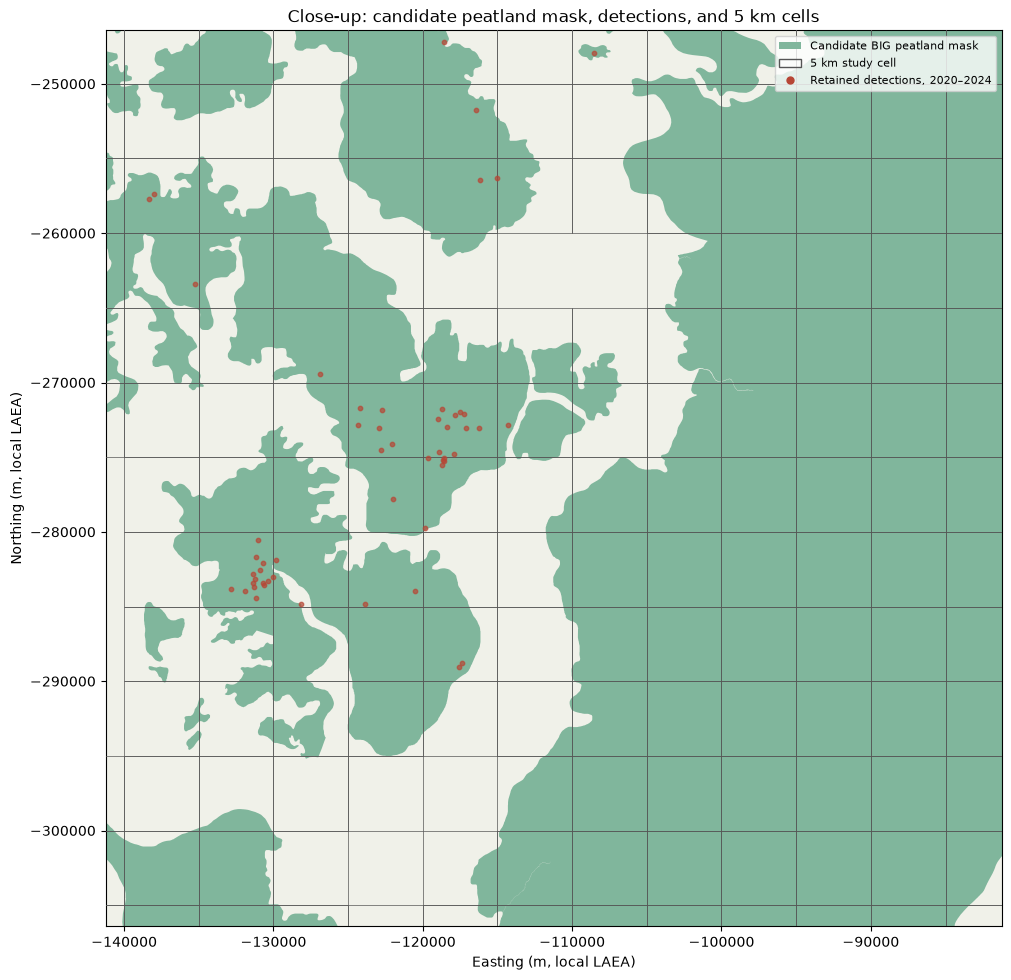

In [19]:
# Verify the retained point coordinates before drawing the map.
peat_x, peat_y = to_grid.transform(
    peat_fires["longitude"].to_numpy(),
    peat_fires["latitude"].to_numpy(),
)
retained_points = shapely.points(peat_x, peat_y)
print("All retained detection coordinates are inside or on the candidate BIG mask.")

# Display a 60 × 60 km window in southern Kalimantan.
center_x, center_y = to_grid.transform(113, -2.5)
radius_m = 30_000
nearby_cells = study_grid.loc[
    (study_grid["x_min_m"] < center_x + radius_m)
    & (study_grid["x_min_m"] + CELL_M > center_x - radius_m)
    & (study_grid["y_min_m"] < center_y + radius_m)
    & (study_grid["y_min_m"] + CELL_M > center_y - radius_m)
]

fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
for province in provinces:
    plot_polygon(
        province, ax=ax, add_points=False,
        facecolor="#f0f1e9", edgecolor="#666666", linewidth=0.5,
        zorder=1,
    )
plot_polygon(
    mapped_in_study, ax=ax, add_points=False,
    facecolor="#80b69c", edgecolor="none", zorder=2,
)

for cell in nearby_cells.itertuples():
    square = shapely.box(
        cell.x_min_m, cell.y_min_m,
        cell.x_min_m + CELL_M, cell.y_min_m + CELL_M,
    )
    plot_polygon(
        square, ax=ax, add_points=False,
        facecolor="none", edgecolor="#555555", linewidth=0.5,
        zorder=3,
    )

# Draw detections last so grid lines cannot hide them.
ax.scatter(peat_x, peat_y, s=10, color="#b74635", alpha=0.7, zorder=4)
ax.set(
    xlim=(center_x - radius_m, center_x + radius_m),
    ylim=(center_y - radius_m, center_y + radius_m),
    xlabel="Easting (m, local LAEA)",
    ylabel="Northing (m, local LAEA)",
    title="Close-up: candidate peatland mask, detections, and 5 km cells",
)
ax.set_aspect("equal")
ax.legend(handles=[
    Patch(facecolor="#80b69c", edgecolor="none", label="Candidate BIG peatland mask"),
    Patch(facecolor="none", edgecolor="#555555", label="5 km study cell"),
    plt.Line2D([], [], marker="o", linestyle="none", color="#b74635",
               markersize=5, label="Retained detections, 2020–2024"),
], loc="upper right", fontsize=8)
fig.savefig(OUTPUT_DIR / "firms_peatland_grid_closeup.png", dpi=180, facecolor="white")
plt.show()

## 14. Add CHIRPS rainfall

Match each 5 km cell center to a CHIRPS pixel. Two coastal cells fall on pixels without rainfall data. For those cells, use the nearest source pixel with data, just as we do for coastal ERA5 cells. The replacement pixels are about 4–5 km from the cell centers. Use each day's observed rainfall from that pixel; do not replace missing rainfall with zero.

In [20]:
# Match each 5 km cell center to a CHIRPS pixel.
cell_lon, cell_lat = to_lonlat.transform(
    study_grid["x_center_m"], study_grid["y_center_m"]
)
with np.load(ROOT / "data/interim/chirps_v2/chirps_v2_kalimantan_2020.npz") as source:
    rain_lat = source["latitude"]
    rain_lon = source["longitude"]
    rain_row = np.abs(rain_lat[:, None] - cell_lat).argmin(axis=0)
    rain_col = np.abs(rain_lon[:, None] - cell_lon).argmin(axis=0)
    valid_pixels = np.isfinite(source["precipitation_mm_day"]).all(axis=0)

# Use the nearest valid pixel where the closest pixel is masked.
valid_rows, valid_cols = np.where(valid_pixels)
valid_x, valid_y = to_grid.transform(rain_lon[valid_cols], rain_lat[valid_rows])
missing_cells = np.where(~valid_pixels[rain_row, rain_col])[0]
rain_fallback_distance_m = []
for i in missing_cells:
    x = study_grid.iloc[i]["x_center_m"]
    y = study_grid.iloc[i]["y_center_m"]
    distance_squared = (valid_x - x)**2 + (valid_y - y)**2
    nearest = distance_squared.argmin()
    rain_row[i], rain_col[i] = valid_rows[nearest], valid_cols[nearest]
    rain_fallback_distance_m.append(np.sqrt(distance_squared[nearest]))

if rain_fallback_distance_m and max(rain_fallback_distance_m) > 10_000:
    raise ValueError("A CHIRPS replacement pixel is more than 10 km away")

rainfall_parts = []
rainfall_dates = []
for year in range(2020, 2025):
    file = ROOT / f"data/interim/chirps_v2/chirps_v2_kalimantan_{year}.npz"
    with np.load(file) as source:
        rainfall_parts.append(source["precipitation_mm_day"][:, rain_row, rain_col])
        rainfall_dates.extend(source["dates"])

if rainfall_dates != dates.strftime("%Y-%m-%d").tolist():
    raise ValueError("CHIRPS dates do not match the fire-label dates")

# Rainfall is (date, cell). The fire table is (cell, date).
rainfall = np.concatenate(rainfall_parts)
if not np.isfinite(rainfall).all():
    raise ValueError("CHIRPS rainfall is still missing for some cell-days")
daily_labels["precipitation_mm_day"] = rainfall.T.ravel()
print("Rainfall added; missing cell-days:", daily_labels["precipitation_mm_day"].isna().sum())
print("Coastal cells using a nearby pixel:", len(missing_cells))
for i, distance in zip(missing_cells, rain_fallback_distance_m):
    print(study_grid.iloc[i]["cell_id"], "→", round(distance / 1000, 2), "km")

Rainfall added; missing cell-days: 0
Coastal cells using a nearby pixel: 2
kp5_c81_r73 → 4.55 km
kp5_c82_r80 → 4.27 km


## 15. Add ERA5-Land temperature and soil water

Sample the nearest ERA5 source pixel. For coastal cells where that pixel has no data, find the nearest valid pixel within 20 km. Convert temperature to Celsius and add both weather columns to the same daily table.


In [21]:
# Find the nearest ERA5 pixel for each study cell.
with np.load(ROOT / "data/interim/era5_land_daily/era5_land_kalimantan_2020.npz") as source:
    era_lat = source["latitude"]
    era_lon = source["longitude"]
    valid_pixels = np.isfinite(source["temperature_2m_K"][0])
    era_row = np.abs(era_lat[:, None] - cell_lat).argmin(axis=0)
    era_col = np.abs(era_lon[:, None] - cell_lon).argmin(axis=0)

# Some coastal ERA5 pixels have no data. Use the nearest valid source pixel.
valid_rows, valid_cols = np.where(valid_pixels)
valid_x, valid_y = to_grid.transform(era_lon[valid_cols], era_lat[valid_rows])
missing_cells = np.where(~valid_pixels[era_row, era_col])[0]
fallback_distance_m = np.zeros(len(study_grid))
for i in missing_cells:
    x = study_grid.iloc[i]["x_center_m"]
    y = study_grid.iloc[i]["y_center_m"]
    squared_distance = (valid_x - x)**2 + (valid_y - y)**2
    nearest = squared_distance.argmin()
    fallback_distance_m[i] = np.sqrt(squared_distance[nearest])
    era_row[i], era_col[i] = valid_rows[nearest], valid_cols[nearest]

if fallback_distance_m.max() > 20_000:
    raise ValueError("An ERA5 source pixel is more than 20 km from its study cell")

temperature_parts = []
soil_water_parts = []
era_dates = []
for year in range(2020, 2025):
    file = ROOT / f"data/interim/era5_land_daily/era5_land_kalimantan_{year}.npz"
    with np.load(file) as source:
        temperature_parts.append(source["temperature_2m_K"][:, era_row, era_col] - 273.15)
        soil_water_parts.append(source["soil_water_layer1_fraction"][:, era_row, era_col])
        era_dates.extend(source["dates"])

if era_dates != dates.strftime("%Y-%m-%d").tolist():
    raise ValueError("ERA5 dates do not match the fire-label dates")

daily_labels["temperature_2m_C"] = np.concatenate(temperature_parts).T.ravel()
daily_labels["soil_water_layer1_fraction"] = np.concatenate(soil_water_parts).T.ravel()
print("ERA5 added; coastal cells using a nearby pixel:", len(missing_cells))
print("Farthest nearby pixel:", round(fallback_distance_m.max() / 1000, 1), "km")


ERA5 added; coastal cells using a nearby pixel: 69
Farthest nearby pixel: 17.3 km


## 16. Check the daily fire and weather table

At this stage, each cell and date has a fire label, rainfall, temperature, and modeled surface soil water. The table stays in memory while we add the remaining spatial variables.


In [22]:
model_table_dir = ROOT / "data/interim/model_table"
model_table_dir.mkdir(parents=True, exist_ok=True)
print("Cell-days:", len(daily_labels))
print("Fire-positive cell-days:", daily_labels["fire_detected"].sum())
print("Missing values by column:")
print(daily_labels.isna().sum().to_string())
daily_labels.head()


Cell-days: 6416424
Fire-positive cell-days: 1009
Missing values by column:
cell_id                       0
acq_date                      0
detection_count               0
fire_detected                 0
precipitation_mm_day          0
temperature_2m_C              0
soil_water_layer1_fraction    0


,cell_id,acq_date,detection_count,fire_detected,precipitation_mm_day,temperature_2m_C,soil_water_layer1_fraction
0,kp5_c-48_r-77,2020-01-01,0,0,11.338016,26.928497,0.323606
1,kp5_c-48_r-77,2020-01-02,0,0,15.117354,26.921143,0.326666
2,kp5_c-48_r-77,2020-01-03,0,0,3.779339,26.822235,0.327724
3,kp5_c-48_r-77,2020-01-04,0,0,0.000000,27.304840,0.325343
4,kp5_c-48_r-77,2020-01-05,0,0,18.896692,26.661835,0.339996


## 17. Candidate MODIS aggregation for review

Mahdiyasa et al. (2026) say that all variables were resampled to a 5 × 5 km grid and categorical land-cover labels were one-hot encoded. They do **not** specify the MODIS classification band, how smaller land-cover pixels were summarized inside a 5 km cell, or which annual map was assigned to each date.

The code below is our **candidate reconstruction**: use the most common `LC_Type1` (IGBP) class across each full 5 km square. It saves one class per cell and annual map, including water (class 17), for review. The next section attaches those classes to the daily table.


In [23]:
import rasterio
from rasterio.transform import Affine
from rasterio.warp import Resampling, reproject

# Set up a raster that follows our 5 km grid, with north at the top.
left_col = grid["grid_col"].min()
top_row = grid["grid_row"].max()
width = grid["grid_col"].max() - left_col + 1
height = top_row - grid["grid_row"].min() + 1
grid_transform = Affine(CELL_M, 0, left_col * CELL_M,
                        0, -CELL_M, (top_row + 1) * CELL_M)
cell_row = (top_row - study_grid["grid_row"]).to_numpy()
cell_col = (study_grid["grid_col"] - left_col).to_numpy()

land_cover_by_year = {}
for year in range(2020, 2025):
    file = ROOT / f"data/interim/modis_landcover/modis_mcd12q1_061_kalimantan_{year}.tif"
    with rasterio.open(file) as source:
        land_cover_grid = np.zeros((height, width), dtype=np.uint8)
        reproject(
            source=rasterio.band(source, 1),
            destination=land_cover_grid,
            src_transform=source.transform,
            src_crs=source.crs,
            dst_transform=grid_transform,
            dst_crs=GRID_CRS_PROJ,
            dst_nodata=0,
            resampling=Resampling.mode,
        )
    land_cover_by_year[year] = land_cover_grid[cell_row, cell_col]

modis_annual = pd.DataFrame(land_cover_by_year, index=study_grid["cell_id"])
modis_annual.index.name = "cell_id"
if (modis_annual == 0).any().any():
    raise ValueError("Some study cells have no MODIS class")

modis_path = ROOT / "data/interim/model_table/modis_landcover_annual_5km.csv"
modis_annual.to_csv(modis_path)
print("Saved annual MODIS classes for", len(modis_annual), "study cells")
print("Cells classified mostly as water by year:")
print((modis_annual == 17).sum().to_string())
modis_annual.head()


Saved annual MODIS classes for 3512 study cells
Cells classified mostly as water by year:
2020    38
2021    39
2022    40
2023    40
2024    39


,2020,2021,2022,2023,2024
cell_id,,,,,
kp5_c-48_r-77,2,2,2,8,8
kp5_c-47_r-77,8,8,8,8,8
kp5_c-46_r-77,8,8,2,8,8
kp5_c-45_r-77,11,11,11,11,11
kp5_c-48_r-76,2,2,2,2,2


## 18. Add MODIS classes to the daily table

The paper one-hot encodes categorical land cover, but does not say which annual MODIS map was assigned to each daily record. For this **retrospective reconstruction**, use the map from the same calendar year as the record. For example, 2024 records receive the 2024 map. This is our assumption, not a rule stated by the paper. It uses a completed annual map and therefore is not a feature that would necessarily have been available at the start of that year.

Keep the integer class for interpretation and add one binary column for each observed class. Model training should use the binary columns, not the integer class as a numeric predictor.


In [24]:
# The MODIS table has one class per study cell and map year.
# daily_labels was built in cell order, with all dates for each cell.
classes_by_cell_and_date = np.zeros((len(study_grid), len(dates)), dtype=np.uint8)
for year in range(2020, 2025):
    days_in_year = dates.year == year
    classes_by_cell_and_date[:, days_in_year] = modis_annual[year].to_numpy()[:, None]

if (classes_by_cell_and_date == 0).any():
    raise ValueError("A daily record has no MODIS land-cover class")

daily_labels["land_cover_map_year"] = daily_labels["acq_date"].dt.year.astype("int16")
daily_labels["land_cover_igbp"] = classes_by_cell_and_date.ravel()

land_cover_columns = []
for class_code in sorted(np.unique(classes_by_cell_and_date)):
    column = f"land_cover_{class_code}"
    daily_labels[column] = (daily_labels["land_cover_igbp"] == class_code).astype("uint8")
    land_cover_columns.append(column)

print("MODIS classes added for all cell-days")
print("One-hot columns:", ", ".join(land_cover_columns))
print("Water-dominant cell-days:", int((daily_labels["land_cover_igbp"] == 17).sum()))


MODIS classes added for all cell-days
One-hot columns: land_cover_2, land_cover_8, land_cover_9, land_cover_10, land_cover_11, land_cover_12, land_cover_13, land_cover_14, land_cover_17
Water-dominant cell-days: 71617


## 19. Candidate GHSL distance to built-up surface

The paper uses a GHSL-derived distance to human activity but does not identify the exact GHSL layer, built-up threshold, or distance method. Our candidate uses the downloaded 2020 GHS-BUILT-S layer. A 100 m pixel counts as built-up when its `built_surface` value is greater than zero; `65535` is missing data. For each 5 km study cell, measure the projected distance from its center to the center of the nearest built-up pixel. Nearby pixels outside Kalimantan can also be the closest, because the download includes a surrounding buffer. This is a proxy for built structures, not every kind of human activity.


In [25]:
from scipy.spatial import cKDTree

file = ROOT / "data/interim/ghsl_built_surface/ghsl_built_surface_2020_kalimantan_buffered.tif"
built_x_parts = []
built_y_parts = []
with rasterio.open(file) as source:
    to_study_grid = Transformer.from_crs(source.crs, GRID_CRS, always_xy=True)
    pixel_grid = source.transform

    # Read in small pieces so the 100 m source raster fits comfortably in memory.
    for _, window in source.block_windows(1):
        pixels = source.read(1, window=window)
        rows, cols = np.where((pixels > 0) & (pixels != source.nodata))
        if len(rows) == 0:
            continue
        x = pixel_grid.c + (window.col_off + cols + 0.5) * pixel_grid.a
        y = pixel_grid.f + (window.row_off + rows + 0.5) * pixel_grid.e
        study_x, study_y = to_study_grid.transform(x, y)
        built_x_parts.append(np.asarray(study_x, dtype=np.float32))
        built_y_parts.append(np.asarray(study_y, dtype=np.float32))

built_x = np.concatenate(built_x_parts)
built_y = np.concatenate(built_y_parts)
built_points = np.column_stack([built_x, built_y])
cell_points = study_grid[["x_center_m", "y_center_m"]].to_numpy()
distance_m, _ = cKDTree(built_points).query(cell_points)

# The same 2020 GHSL distance is attached to every date for each cell.
ghsl_distance = pd.Series(distance_m, index=study_grid["cell_id"])
daily_labels["distance_to_built_m"] = daily_labels["cell_id"].map(ghsl_distance)

print("Built-up source pixels:", f"{len(built_points):,}")
print("Distance to built-up surface (km), median/max:",
      round(np.median(distance_m) / 1000, 2),
      round(distance_m.max() / 1000, 2))


Built-up source pixels: 2,088,635
Distance to built-up surface (km), median/max: 2.08 30.9


## 20. Save the current combined table

Save the cell-level GHSL distances and the daily table with fire labels, weather, one-hot MODIS land cover, and distance. The same-year MODIS rule and the GHSL rule are documented reconstruction choices. For the two coastal CHIRPS cells, rainfall comes from a nearby valid pixel. Prediction-time availability still needs review before this table is used for training.


In [26]:
ghsl_cells = pd.DataFrame({
    "cell_id": study_grid["cell_id"],
    "distance_to_built_m": distance_m,
})
ghsl_cells.to_csv(model_table_dir / "ghsl_distance_5km.csv", index=False)

output = model_table_dir / "daily_features_interim.parquet"
daily_labels.to_parquet(output, index=False)
print("Saved:", output.relative_to(ROOT))
print("Rows:", f"{len(daily_labels):,}")
print("Missing values by column:")
print(daily_labels.isna().sum().to_string())


Saved: data/interim/model_table/daily_features_interim.parquet
Rows: 6,416,424
Missing values by column:
cell_id                       0
acq_date                      0
detection_count               0
fire_detected                 0
precipitation_mm_day          0
temperature_2m_C              0
soil_water_layer1_fraction    0
land_cover_map_year           0
land_cover_igbp               0
land_cover_2                  0
land_cover_8                  0
land_cover_9                  0
land_cover_10                 0
land_cover_11                 0
land_cover_12                 0
land_cover_13                 0
land_cover_14                 0
land_cover_17                 0
distance_to_built_m           0


## 21. Split by year and scale continuous inputs

The paper trains on 2020–2023 and tests on 2024. Save those years separately, with `fire_detected` as the observed target. Scale rainfall, temperature, soil water, and built-up distance using the **2020–2023 minimum and maximum** for each variable; apply those same ranges to 2024. This keeps information from the test year out of the scaling step. The paper says it uses min–max scaling but does not state which years supplied the minimum and maximum.

The saved tables keep cell ID and date for tracing rows, plus the scaled continuous inputs, one-hot land cover, and target. They describe **same-day fire labels**. A 3- or 10-day forecast will need a separately defined future target and input-time rule. Because the 2024 rainfall maximum exceeds the training maximum, two 2024 scaled rainfall values will be slightly above 1; they are left as measured rather than clipped.

In [27]:
continuous_columns = [
    "precipitation_mm_day",
    "temperature_2m_C",
    "soil_water_layer1_fraction",
    "distance_to_built_m",
]
train_rows = daily_labels["acq_date"].dt.year <= 2023
test_rows = daily_labels["acq_date"].dt.year == 2024

scaling = pd.DataFrame({
    "train_min": daily_labels.loc[train_rows, continuous_columns].min(),
    "train_max": daily_labels.loc[train_rows, continuous_columns].max(),
})
scaling.index.name = "feature"
scaling.to_csv(model_table_dir / "training_scaling_ranges.csv")

columns = ["cell_id", "acq_date", "fire_detected", *continuous_columns, *land_cover_columns]
train_data = daily_labels.loc[train_rows, columns].copy()
test_data = daily_labels.loc[test_rows, columns].copy()

for feature in continuous_columns:
    minimum = scaling.loc[feature, "train_min"]
    span = scaling.loc[feature, "train_max"] - minimum
    scaled_name = feature + "_scaled"
    train_data[scaled_name] = ((train_data[feature] - minimum) / span).astype("float32")
    test_data[scaled_name] = ((test_data[feature] - minimum) / span).astype("float32")

train_data = train_data.drop(columns=continuous_columns)
test_data = test_data.drop(columns=continuous_columns)
train_data.to_parquet(model_table_dir / "train_2020_2023.parquet", index=False)
test_data.to_parquet(model_table_dir / "test_2024.parquet", index=False)

print("Training rows:", f"{len(train_data):,}")
print("Test rows:", f"{len(test_data):,}")
print("Training fire-positive rows:", int(train_data["fire_detected"].sum()))
print("Test fire-positive rows:", int(test_data["fire_detected"].sum()))
print("2024 rainfall values above the training maximum:",
      int((test_data["precipitation_mm_day_scaled"] > 1).sum()))
print("Missing values in either split:",
      int(train_data.isna().sum().sum() + test_data.isna().sum().sum()))
scaling

Training rows: 5,131,032
Test rows: 1,285,392
Training fire-positive rows: 939
Test fire-positive rows: 70
2024 rainfall values above the training maximum: 2
Missing values in either split: 0


,train_min,train_max
feature,,
precipitation_mm_day,0.000000,127.191032
temperature_2m_C,21.640076,31.822449
soil_water_layer1_fraction,0.050828,0.604857
distance_to_built_m,3.723917,30903.356802
